# GRSOpt — demo

| Step | Function |
| --- | --- |
| 1 | `backward_selection` / `forward_selection` — greedy selection inside 5-fold CV |
| 2 | `grsoptimizer.cross_validate` — hyperparameter tuning |
| 3 | `grsoptimizer.optimize` — recalibrate the betas of the selected signature |
| 4 | `calculate_auc`, `grs_pic`, `roc_pic` — evaluation and figures |

**Data.** Discovery cohort: 141 T1D and 385 HC. Independent validation cohort: 107 T1D and 53 HC. Beta coefficients are taken from T1D GRS1 (Oram et al. 2016) and T1D GRS2 (Sharp et al. 2019).

In [1]:
import numpy as np
import pandas as pd

import grsopt
from grsopt import (
    OptimizerConfig,
    SelectionConfig,
    backward_selection,
    calculate_auc,
    forward_selection,
    grs_pic,
    grsoptimizer,
    rank_snps_by_importance,
    roc_pic,
)

<frozen importlib._bootstrap>:491: RuntimeWarning: The global interpreter lock (GIL) has been enabled to load module 'sklearn.__check_build._check_build', which has not declared that it can run safely without the GIL. To override this behavior and keep the GIL disabled (at your own risk), run with PYTHON_GIL=0 or -Xgil=0.


In [2]:
cd ./data

/Users/labweng/Desktop/t1d论文/grsopt/data


In [3]:
# Discovery cohort (141 T1D and 385 HC) and independent validation cohort (107 T1D and 53 HC).
train_df = pd.read_csv('./train.csv', index_col=0)
val_df = pd.read_csv('./validation.csv', index_col=0)

In [4]:
# Published beta coefficients for T1D GRS1 (Oram et al. 2016) and GRS2 (Sharp et al. 2019).
# One coefficient per locus: keep the first row for duplicated loci.
beta_df = pd.read_csv('./T1DGRS1&2_beta.csv', index_col=0)
beta_df = beta_df.drop_duplicates('loci').set_index('loci')
beta = beta_df['beta']                       # pd.Series indexed by SNP

# Keep only the SNPs that carry a published beta coefficient in both cohorts.
snps = [c for c in train_df.columns if c in beta.index and c in val_df.columns]

X = train_df.loc[:, snps]
X_val = val_df.loc[:, snps]
beta = beta.loc[snps]

# Encode disease status: HC = 0, T1D = 1.
mapping = {"HC": 0, "T1D": 1}
y = train_df['Disease'].map(mapping)
y_val = val_df['Disease'].map(mapping)

print(f"SNPs with a published beta: {len(snps)}")
print(f"Discovery set : {X.shape}  ({int(y.sum())} T1D / {int((1 - y).sum())} HC)")
print(f"Validation set: {X_val.shape}  ({int(y_val.sum())} T1D / {int((1 - y_val).sum())} HC)")

SNPs with a published beta: 54
Discovery set : (526, 54)  (141 T1D / 385 HC)
Validation set: (160, 54)  (107 T1D / 53 HC)


In [5]:
X.head(2)

,1:113834946:A:G,1:206766559:G:A,2:162267541:C:T,2:203874196:G:A,4:122456825:A:C,6:29972123:C:T,6:90248512:C:G,6:126377573:A:G,7:50959497:A:C,10:6055320:T:C,...,18:69859408:T:C,9:4290823:A:T,13:99429512:C:T,22:37195278:G:A,6:159044945:T:C,14:100840110:T:C,12:9733403:G:A,2:162254026:A:G,19:10381598:C:T,10:6087680:C:T
0,2.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,2.0,0.0,...,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,2.0,0.0,0.0,0.0,1.0,0.0,1.0,2.0,2.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0


In [6]:
beta.head()

loci
1:113834946:A:G    0.672944
1:206766559:G:A    0.173953
2:162267541:C:T    0.148420
2:203874196:G:A    0.198851
4:122456825:A:C    0.113329
Name: beta, dtype: float64

## 1. Backward selection with 5-fold cross-validation

Starting from all SNPs, the least important SNP is removed first. For every candidate subset the betas are re-optimised on the training part of the fold and scored on the held-out part; a deletion is kept only if that AUC improves by more than `margin`. The loop stops when nothing further can be deleted or when `end_n` SNPs remain. Because each fold optimises and evaluates on its own split, the retained sets can differ between folds — the final signature keeps the SNPs selected in at least `retention_threshold` of the folds.

*(The per-fold removals are printed as the cell runs. Use `verbose=True` on `OptimizerConfig` to also see the optimizer output.)*

In [7]:
sel = SelectionConfig(
    direction="backward",
    cv_folds=5,
    start_n=None,               # backward: start from all SNPs
    end_n=1,                   # stop when 10 SNPs remain
    margin=0.0,                 # accept a deletion only if the fold AUC does not drop
    retention_threshold=0.5,    # keep SNPs retained in >= 4 of 5 folds
)
opt = OptimizerConfig(
    max_iter=200,
    n_initial=3,                # number of random restarts per fold
    regularization_strength=0.1,
    noise_scale=0.5,
    loss="rank",                # 'rank' targets AUC, 'log' is cross-entropy
    verbose=False,
)

res = backward_selection(X, y, beta, sel, opt)

[fold 0] removed 2:203874196:G:A: validation AUC 0.7371 -> 0.7385 (Δ +0.0013)
[fold 0] removed 21:42405613:G:C: validation AUC 0.7385 -> 0.7403 (Δ +0.0018)
[fold 0] removed 14:68796882:T:C: validation AUC 0.7403 -> 0.7416 (Δ +0.0013)
[fold 0] removed 16:28528527:C:T: validation AUC 0.7416 -> 0.7429 (Δ +0.0013)
[fold 0] removed 22:30185733:C:T: validation AUC 0.7429 -> 0.7488 (Δ +0.0058)
[fold 0] removed 12:56080696:A:G: validation AUC 0.7488 -> 0.7501 (Δ +0.0013)
[fold 0] removed 11:2160994:A:T: validation AUC 0.7501 -> 0.7541 (Δ +0.0040)
[fold 0] removed 19:46705224:T:C: validation AUC 0.7541 -> 0.7550 (Δ +0.0009)
[fold 0] removed 15:78944951:C:T: validation AUC 0.7550 -> 0.7559 (Δ +0.0009)
[fold 0] removed 6:32427740:T:C: validation AUC 0.7559 -> 0.7577 (Δ +0.0018)
[fold 0] removed 16:11086016:A:G: validation AUC 0.7577 -> 0.7622 (Δ +0.0045)
[fold 0] removed 12:56088396:T:G: validation AUC 0.7622 -> 0.7644 (Δ +0.0022)
[fold 0] removed 11:2159830:T:G: validation AUC 0.7644 -> 0.7685 (

In [9]:
final_snps = res["selected_snps"]
X_sel = X[final_snps]
beta_sel = beta.loc[final_snps]

print(f"Final signature: {len(final_snps)} SNPs")

Final signature: 12 SNPs


## 2. Forward selection 

In [10]:
sel_fwd = SelectionConfig(
    direction="forward",
    cv_folds=5,
    start_n=10,                 # forward: start from the 10 most important SNPs
    end_n=20,                   # stop when 20 SNPs are reached
    margin=0.0,
    retention_threshold=0.8,
)

res_fwd = forward_selection(X, y, beta, sel_fwd, opt)
print(f"Forward selection: {len(res_fwd['selected_snps'])} SNPs, "
      f"mean held-out AUC {res_fwd['mean_auc']:.4f} +/- {res_fwd['std_auc']:.4f}")

[fold 0] added 9:4290823:A:T: validation AUC 0.7880 -> 0.7920 (Δ +0.0040)
[fold 0] added 12:53192075:C:T: validation AUC 0.7920 -> 0.7940 (Δ +0.0020)
[fold 0] added 10:6087680:C:T: validation AUC 0.7940 -> 0.7994 (Δ +0.0054)
[fold 0] added 4:122408207:G:A: validation AUC 0.7994 -> 0.8007 (Δ +0.0013)
[fold 0] added 6:31439802:G:A: validation AUC 0.8007 -> 0.8047 (Δ +0.0040)
[fold 0] added 16:28580209:G:A: validation AUC 0.8047 -> 0.8079 (Δ +0.0031)
[fold 0] added 15:38610275:A:C: validation AUC 0.8079 -> 0.8083 (Δ +0.0004)
[fold 0] added 1:206766559:G:A: validation AUC 0.8083 -> 0.8106 (Δ +0.0022)
[fold 0] added 20:1629905:T:C: validation AUC 0.8106 -> 0.8128 (Δ +0.0022)
[fold 0] added 11:2160994:A:T: validation AUC 0.8128 -> 0.8133 (Δ +0.0004)
[fold 1] added 9:4290823:A:T: validation AUC 0.8270 -> 0.8284 (Δ +0.0014)
[fold 1] added 18:12809341:A:G: validation AUC 0.8284 -> 0.8288 (Δ +0.0005)
[fold 1] added 12:53192075:C:T: validation AUC 0.8288 -> 0.8293 (Δ +0.0005)
[fold 1] added 6:299

## 3. Hyperparameter tuning of the beta optimizer

`cross_validate` runs `optimize` on each training fold for every combination in `param_grid` and returns the combination with the highest mean held-out AUC. Valid grid keys are `regularization_strength`, `n_initial` and `noise_scale`; `loss` is passed separately.

In [11]:
tuner = grsoptimizer(original_betas=beta_sel)

param_grid = {
    "regularization_strength": [0.001, 0.01, 0.05, 0.1],
    "noise_scale": [0.1, 0.3, 0.8],
}

cv_res = tuner.cross_validate(X_sel, y, param_grid, cv_folds=5, loss="rank")

In [12]:
print(f"Best parameters: {cv_res['best_params']}")
print(f"Best mean held-out AUC: {cv_res['best_auc']:.4f}")

Best parameters: {'regularization_strength': 0.01, 'noise_scale': 0.1}
Best mean held-out AUC: 0.8348


## 4. Recalibrate the betas of the final signature

In [13]:
optimizer = grsoptimizer(
    original_betas=beta_sel,
    regularization_strength=cv_res["best_params"]["regularization_strength"],
    noise_scale=cv_res["best_params"]["noise_scale"],
    n_initial=5,
    max_iter=200,
    loss="rank",
    verbose=True,
)

result = optimizer.optimize(X_sel, y)


=== Optimization Results ===
Original model AUC: 0.8011
Optimized AUC: 0.8509
AUC improvement: 0.0498


In [14]:
beta_optimized = pd.Series(result["optimized_betas"], index=final_snps)

beta_table = pd.DataFrame({
    "beta_original": beta_sel,
    "beta_optimized": beta_optimized,
    "beta_change": beta_optimized - beta_sel,
}).sort_values("beta_change", key=abs, ascending=False)

beta_table

,beta_original,beta_optimized,beta_change
6:32479411:T:A,0.667829,2.023677,1.355847
6:33081532:A:G,-0.494296,-0.162501,0.331796
6:29868825:C:T,0.774727,1.023999,0.249272
16:75213347:T:G,0.246860,0.466394,0.219534
6:90248512:C:G,0.122218,0.303640,0.181422
21:42421219:C:A,0.122218,0.282658,0.160440
6:31376405:T:.,-0.941609,-1.097712,-0.156104
22:30108663:A:G,0.148420,0.271223,0.122803
9:4290823:A:T,0.113329,0.212871,0.099542
18:12809341:A:G,0.182322,0.144118,-0.038204


## 5. Evaluation of the recalibrated score

`calculate_auc` builds the GRS from the selected SNPs and the supplied betas and returns the AUC on the given cohort. 

In [15]:
auc_train_original = calculate_auc(X, y, beta)
auc_train_selected = calculate_auc(X, y, beta_sel, final_snps)
auc_train_optimized = calculate_auc(X, y, beta_optimized, final_snps)

print(f"Discovery set - original   : {auc_train_original:.4f}")
print(f"Discovery set - selected feature   : {auc_train_selected:.4f}")
print(f"Discovery set - selected feature+recalibrated betas: {auc_train_optimized:.4f}")
print(f"Discovery set AUC gain: {auc_train_optimized - auc_train_original:+.4f}")

Discovery set - original   : 0.7126
Discovery set - selected feature   : 0.8011
Discovery set - selected feature+recalibrated betas: 0.8509
Discovery set AUC gain: +0.1383


In [16]:
auc_val_original = calculate_auc(X_val, y_val, beta)
auc_val_selected = calculate_auc(X_val, y_val, beta_sel, final_snps)
auc_val_optimized = calculate_auc(X_val, y_val, beta_optimized, final_snps)

print(f"Validation set - published betas   : {auc_val_original:.4f}")
print(f"Validation set - selected feature   : {auc_val_selected:.4f}")
print(f"Validation set - selected feature+recalibrated betas: {auc_val_optimized:.4f}")
print(f"Validation set AUC gain: {auc_val_optimized - auc_val_original:+.4f}")


Validation set - published betas   : 0.6722
Validation set - selected feature   : 0.6578
Validation set - selected feature+recalibrated betas: 0.7204
Validation set AUC gain: +0.0482


## 6. Figures

`grs_pic` draws the GRS distribution by disease status and `roc_pic` draws the ROC curve; both take a DataFrame with the columns `grs` and `Disease` (raw labels, e.g. `HC` / `T1D`) and an optional `save_path` to write the figure to disk.

### Discovery set — published betas

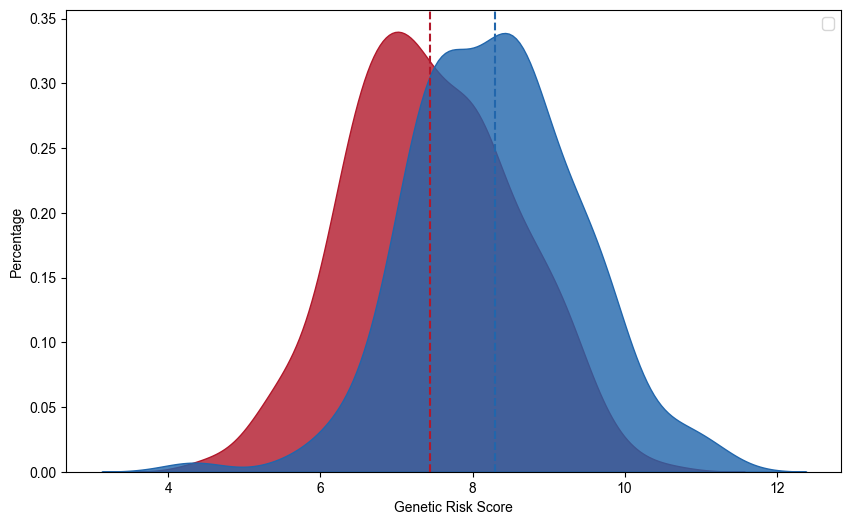

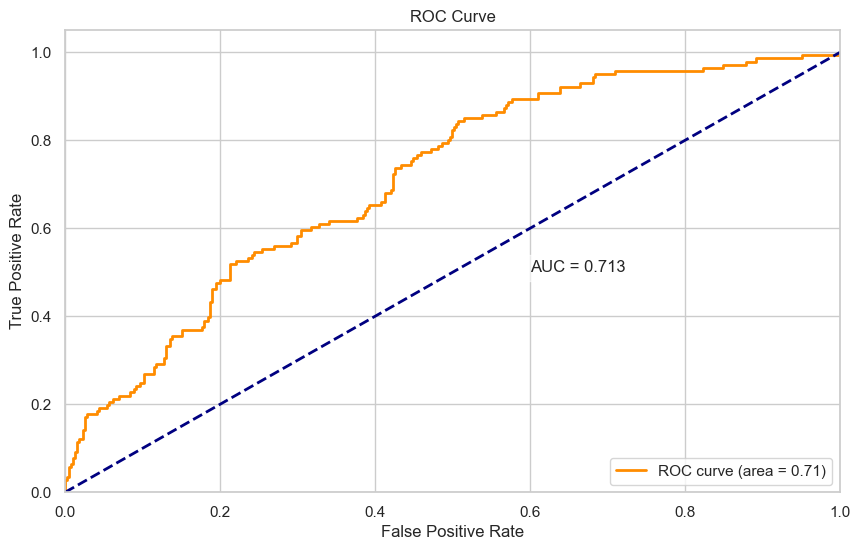

In [17]:
grs_train_ori_df = pd.DataFrame({
    "grs": X.to_numpy() @ beta.to_numpy(),
    "Disease": train_df["Disease"].to_numpy(),
})

grs_pic(grs_train_ori_df, model_name="discovery_published")
roc_pic(grs_train_ori_df, model_name="discovery_published")

### Discovery set — recalibrated betas

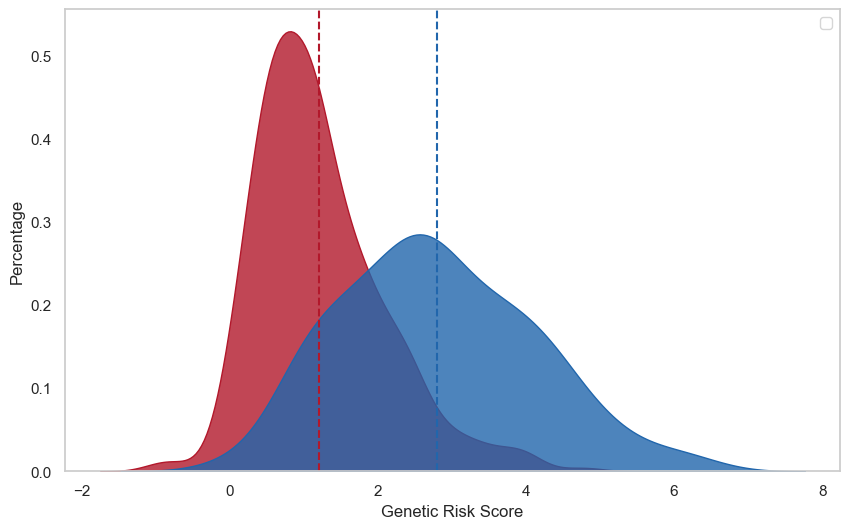

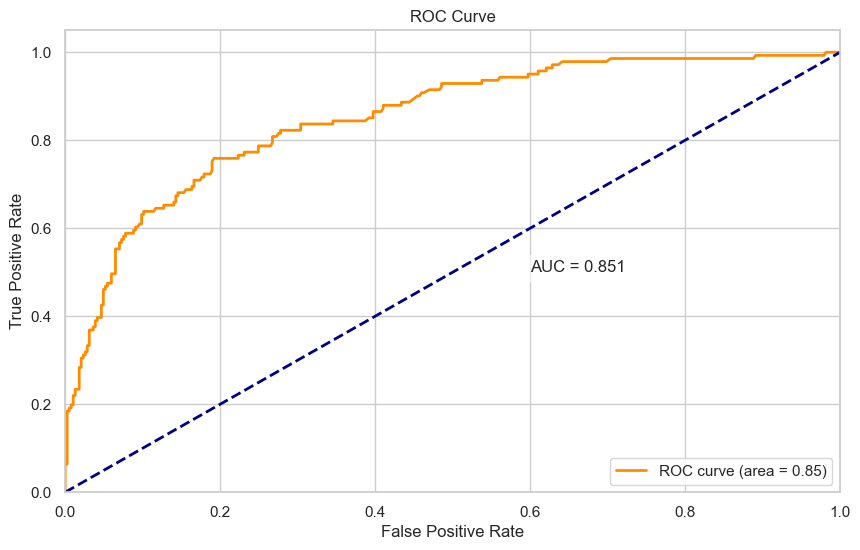

In [19]:
grs_train_df = pd.DataFrame({
    "grs": X_sel.to_numpy() @ beta_optimized.to_numpy(),
    "Disease": train_df["Disease"].to_numpy(),
})

grs_pic(grs_train_df, model_name="discovery_optimized")
roc_pic(grs_train_df, model_name="discovery_optimized")

### Validation set — published betas

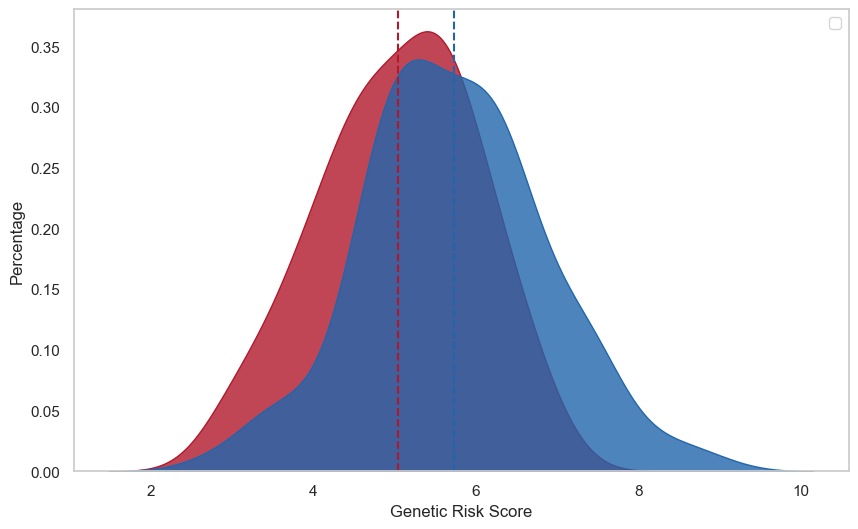

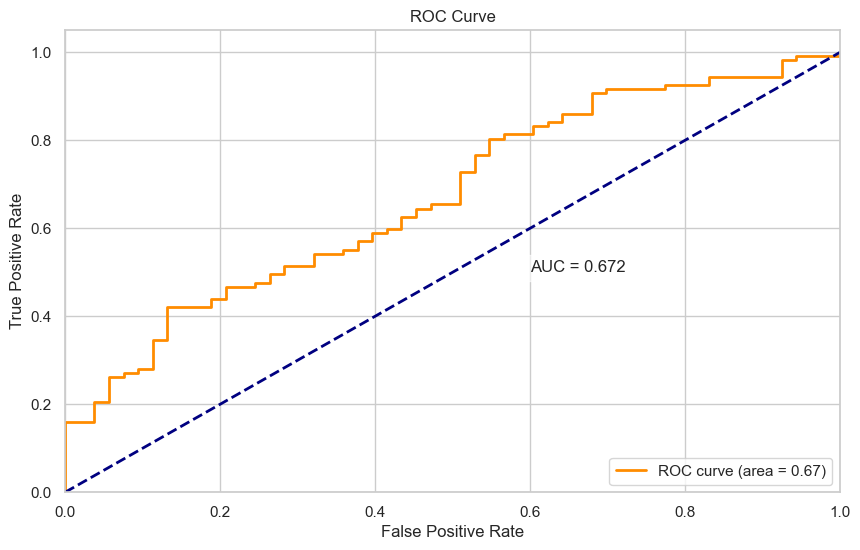

In [21]:
grs_val_ori_df = pd.DataFrame({
    "grs": X_val.to_numpy() @ beta.to_numpy(),
    "Disease": val_df["Disease"].to_numpy(),
})

grs_pic(grs_val_ori_df, model_name="validation_original")
roc_pic(grs_val_ori_df, model_name="validation_original")

### Validation set — recalibrated betas

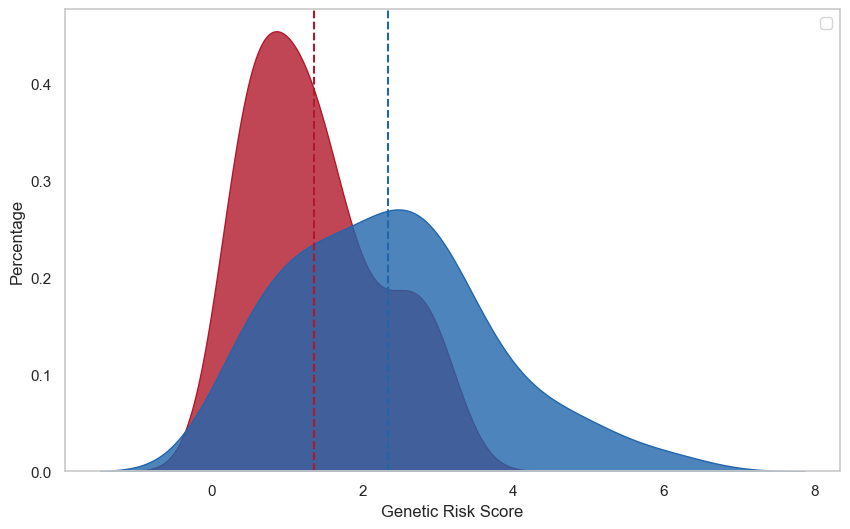

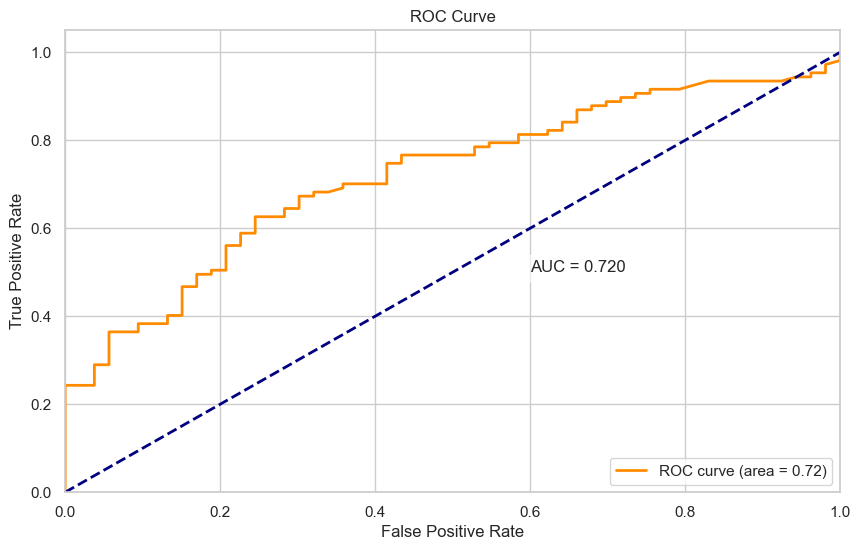

In [22]:
grs_val_df = pd.DataFrame({
    "grs": X_val[final_snps].to_numpy() @ beta_optimized.to_numpy(),
    "Disease": val_df["Disease"].to_numpy(),
})

grs_pic(grs_val_df, model_name="validation_optimized")
roc_pic(grs_val_df, model_name="validation_optimized")